# Reconhecimento de Fonemas via Rede Neural Artificial (MLP)
**Universidade Federal do Maranhão (UFMA)**  
**Centro de Ciências Exatas e Tecnologia (CCET)**  
**Programa de Pós-Graduação em Ciência da Computação (PPGCC / DCCMAPI)**  
**Disciplina:** Redes Neurais Artificiais  
**Professor:** Prof. Dr. Areolino de Almeida Neto  
**Aluno:** Ricardo Diniz  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RicDM/trabalhos_redes_neurais/blob/main/MLP/reconhecimento_fonemas_mlp.ipynb)

---

### Visão Geral
Este notebook implementa uma **Rede Neural Multilayer Perceptron (MLP)** para reconhecimento de 6 classes fonéticas das palavras **DIREITA** (`DI`, `REI`, `TA`) e **ESQUERDA** (`ES`, `QUER`, `DA`).

- **Implementação Manual (From Scratch):** Propagação direta (*forward*), gradientes locais ($\delta$), retropropagação (*backward*), termo momento e erro quadrático médio ($E_{av}$) implementados em **NumPy** com base nas equações deduzidas em sala.
- **Execução Real:** Todos os experimentos, gráficos e métricas são gerados dinamicamente a partir dos dados de áudio na pasta compartilhada `dados/dataset`.
- **Compatibilidade:** Detecção automática de ambiente local ou Google Colab via GitHub.


## 1. Configuração do Ambiente e Localização dos Dados
Importa as bibliotecas necessárias, fixa sementes aleatórias para reprodutibilidade e localiza a pasta compartilhada `dados/dataset`. Caso executado no Google Colab, clona o repositório automaticamente.


In [1]:
import os
import sys
import glob
import math
import subprocess
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Detecção de ambiente (Local vs Google Colab)
IN_COLAB = 'google.colab' in sys.modules
GITHUB_REPO_URL = os.environ.get("GITHUB_REPO_URL", "https://github.com/RicDM/trabalhos_redes_neurais.git")
REPO_DIR = Path("trabalhos_redes_neurais")

if IN_COLAB:
    print("[Google Colab] Ambiente de nuvem detectado!")
    subprocess.run([sys.executable, "-m", "pip", "install", "soundfile", "-q"], check=True)
    if not os.path.exists("../dados/dataset") and not os.path.exists("dados/dataset") and not os.path.exists("trabalhos_redes_neurais/dados/dataset"):
        if not REPO_DIR.exists():
            print(f"[Google Colab] Clonando repositório GitHub: {GITHUB_REPO_URL}...")
            subprocess.run(["git", "clone", GITHUB_REPO_URL, str(REPO_DIR)], check=True)

# Localizador da pasta de dados compartilhada
def localizar_dataset():
    candidatos = [
        Path("../dados/dataset"),                               # Execução dentro de MLP/ (local)
        Path("dados/dataset"),                                  # Execução na raiz do repositório
        Path("trabalhos_redes_neurais/dados/dataset"),         # Google Colab (clone relativo)
        Path("/content/trabalhos_redes_neurais/dados/dataset"), # Google Colab (caminho absoluto)
    ]
    for p in candidatos:
        if p.exists() and (p / "DI").exists() and (p / "DA").exists():
            return p.resolve()
    raise FileNotFoundError("Base de dados 'dados/dataset' não encontrada.")

DATASET_PATH = localizar_dataset()
print(f"[OK] Base de dados compartilhada localizada em: {DATASET_PATH}")

SEED = 42
np.random.seed(SEED)

CLASSES = ["DI", "REI", "TA", "ES", "QUER", "DA"]
LABEL_MAP = {c: i for i, c in enumerate(CLASSES)}
print(f"[OK] Classes fonéticas ({len(CLASSES)}): {CLASSES}")


[OK] Base de dados compartilhada localizada em: /home/rdm/Documentos/Mestrado/redes neurais/Trabalho/dados/dataset
[OK] Classes fonéticas (6): ['DI', 'REI', 'TA', 'ES', 'QUER', 'DA']


## 2. Forma de Onda Temporal e Decomposição Espectral (FFT com Agrupamento)
Carrega um exemplo de áudio para cada uma das 6 classes fonéticas e visualiza o sinal no tempo $x(t)$ junto ao espectro de frequências obtido pela FFT unilateral agrupado em $B = 32$ bandas pela média das amplitudes.


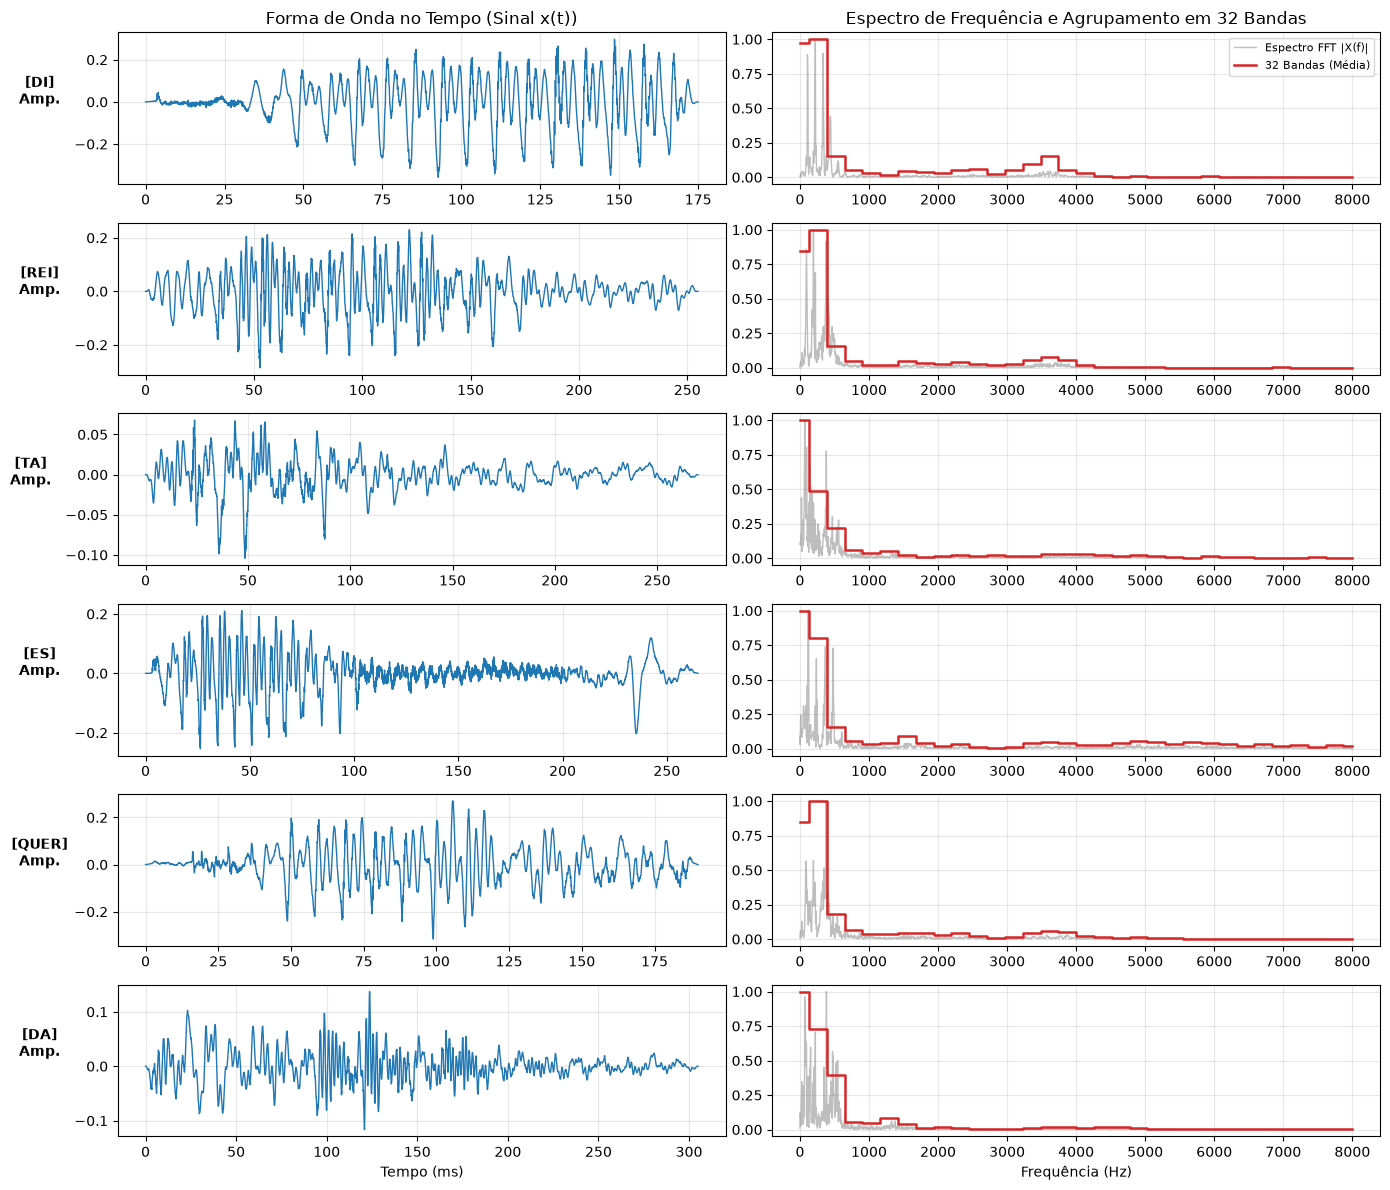

In [2]:
fig, axes = plt.subplots(6, 2, figsize=(14, 12))
for idx, c in enumerate(CLASSES):
    f = sorted(glob.glob(f"{DATASET_PATH}/{c}/*.wav"))[0]
    data, sr = sf.read(f)
    t = np.arange(len(data)) / sr
    
    # Onda temporal
    axes[idx, 0].plot(t * 1000, data, color="#1f77b4", lw=1)
    axes[idx, 0].set_ylabel(f"[{c}]\nAmp.", rotation=0, labelpad=25, fontweight="bold")
    axes[idx, 0].grid(True, alpha=0.3)
    if idx == 0:
        axes[idx, 0].set_title("Forma de Onda no Tempo (Sinal x(t))")
    if idx == 5:
        axes[idx, 0].set_xlabel("Tempo (ms)")
        
    # FFT e 32 bandas
    fft_vals = np.abs(np.fft.rfft(data))
    freqs = np.fft.rfftfreq(len(data), 1.0 / sr)
    bins = np.array_split(fft_vals, 32)
    bin_means = [np.mean(b) if len(b) > 0 else 0.0 for b in bins]
    bin_centers = np.linspace(freqs[0], freqs[-1], 32)
    
    axes[idx, 1].plot(freqs, fft_vals / (np.max(fft_vals) + 1e-6), color="#7f7f7f", alpha=0.5, lw=1, label="Espectro FFT |X(f)|")
    axes[idx, 1].step(bin_centers, bin_means / (np.max(bin_means) + 1e-6), where="mid", color="#d62728", lw=1.8, label="32 Bandas (Média)")
    axes[idx, 1].grid(True, alpha=0.3)
    if idx == 0:
        axes[idx, 1].set_title("Espectro de Frequência e Agrupamento em 32 Bandas")
        axes[idx, 1].legend(loc="upper right", fontsize=8)
    if idx == 5:
        axes[idx, 1].set_xlabel("Frequência (Hz)")

plt.tight_layout()
plt.show()


## 3. Extração dos Vetores de Características
Define a função de extração de características espectrais via FFT e constrói os conjuntos de dados para duas resoluções espectrais ($B = 16$ e $B = 32$ bandas) a fim de possibilitar a análise experimental da dimensionalidade de entrada.


In [3]:
def extrair_features_fft(x, n_bandas=32):
    fft_vals = np.abs(np.fft.rfft(x))
    bins = np.array_split(fft_vals, n_bandas)
    feat = np.array([np.mean(b) if len(b) > 0 else 0.0 for b in bins])
    norm = np.linalg.norm(feat)
    return feat / norm if norm > 0 else feat

def carregar_dataset(n_bandas=32, dataset_path=None):
    dataset_path = dataset_path or DATASET_PATH
    X, y, caminhos = [], [], []
    for c in CLASSES:
        flist = sorted(glob.glob(f"{dataset_path}/{c}/*.wav"))
        for f in flist:
            audio, sr = sf.read(f)
            feat = extrair_features_fft(audio, n_bandas=n_bandas)
            X.append(feat)
            y.append(LABEL_MAP[c])
            caminhos.append(f)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64), caminhos

# Carregamento com 32 bandas (padrão principal) e 16 bandas (para análise comparativa de resolução)
X32_raw, y_raw, caminhos_raw = carregar_dataset(n_bandas=32)
X16_raw, _, _ = carregar_dataset(n_bandas=16)

print(f"[+] Total de amostras carregadas: {len(X32_raw)}")
for c in CLASSES:
    qtd = sum(1 for label in y_raw if label == LABEL_MAP[c])
    print(f"    - Classe {c:<5}: {qtd:2d} amostras")


[+] Total de amostras carregadas: 423
    - Classe DI   : 68 amostras
    - Classe REI  : 68 amostras
    - Classe TA   : 68 amostras
    - Classe ES   : 73 amostras
    - Classe QUER : 73 amostras
    - Classe DA   : 73 amostras


## 4. Particionamento Estratificado dos Dados
Divide os índices das 423 amostras de forma estratificada nas proporções metodológicas:
- **75% Treinamento:** 316 amostras
- **15% Validação:** 64 amostras
- **10% Teste Cego:** 43 amostras


In [4]:
def particionar_indices(y, seed=42):
    idx_all = np.arange(len(y))
    idx_temp, idx_test, y_temp, y_test = train_test_split(
        idx_all, y, test_size=0.10, random_state=seed, stratify=y
    )
    val_ratio = 0.15 / 0.90
    idx_train, idx_val, y_train, y_val = train_test_split(
        idx_temp, y_temp, test_size=val_ratio, random_state=seed, stratify=y_temp
    )
    return idx_train, idx_val, idx_test

idx_train, idx_val, idx_test = particionar_indices(y_raw, seed=SEED)

y_train = y_raw[idx_train]
y_val = y_raw[idx_val]
y_test = y_raw[idx_test]

# Matrizes com 32 bandas
X_train = X32_raw[idx_train]
X_val = X32_raw[idx_val]
X_test = X32_raw[idx_test]

# Matrizes com 16 bandas (para teste de resolução)
X16_train = X16_raw[idx_train]
X16_val = X16_raw[idx_val]
X16_test = X16_raw[idx_test]

print(f"[+] Treinamento : {len(y_train):3d} amostras ({len(y_train)/len(y_raw)*100:.1f}%)")
print(f"[+] Validação   : {len(y_val):3d} amostras ({len(y_val)/len(y_raw)*100:.1f}%)")
print(f"[+] Teste Cego  : {len(y_test):3d} amostras ({len(y_test)/len(y_raw)*100:.1f}%)")


[+] Treinamento : 316 amostras (74.7%)
[+] Validação   :  64 amostras (15.1%)
[+] Teste Cego  :  43 amostras (10.2%)


## 5. Implementação da Rede MLP e Backpropagation Manual (Do Zero)
Classe `MLPManual` construída com **NumPy**:
- **Inicialização de pesos:** Glorot/Xavier para ativações sigmoide/tangente hiperbólica e He para ReLU/Leaky ReLU.
- **Forward:** ativações ocultas e camada de saída softmax.
- **Backward:** cálculo dos gradientes locais $\delta$ em cadeia e atualização de pesos via SGD (com momento $\alpha$) ou Adam adaptativo.
- **Função de Custo:** Erro Quadrático Médio da Rede ($E_{av} = \frac{1}{2P} \sum (d_k - y_k)^2$).


In [5]:
class MLPManual:
    def __init__(self, n_in=32, hidden_layers=[64, 32], n_out=6, activation="leaky_relu", seed=42):
        np.random.seed(seed)
        self.activation = activation
        self.layer_sizes = [n_in] + list(hidden_layers) + [n_out]
        self.num_layers = len(self.layer_sizes) - 1
        
        self.weights = []
        self.biases = []
        self.v_weights = []
        self.v_biases = []
        self.m_weights = []
        self.s_weights = []
        self.m_biases = []
        self.s_biases = []
        
        for i in range(self.num_layers):
            din = self.layer_sizes[i]
            dout = self.layer_sizes[i+1]
            if activation in ["relu", "leaky_relu"]:
                limit = np.sqrt(2.0 / din)
            else:
                limit = np.sqrt(6.0 / (din + dout))
            W = np.random.randn(din, dout) * limit
            b = np.zeros((1, dout))
            self.weights.append(W)
            self.biases.append(b)
            self.v_weights.append(np.zeros_like(W))
            self.v_biases.append(np.zeros_like(b))
            self.m_weights.append(np.zeros_like(W))
            self.s_weights.append(np.zeros_like(W))
            self.m_biases.append(np.zeros_like(b))
            self.s_biases.append(np.zeros_like(b))
        self.t = 0
        
    def _act(self, z):
        if self.activation == "leaky_relu":
            return np.maximum(0.01 * z, z)
        elif self.activation == "relu":
            return np.maximum(0.0, z)
        elif self.activation == "tanh":
            return np.tanh(z)
        elif self.activation == "sigmoid":
            return 1.0 / (1.0 + np.exp(-np.clip(z, -15, 15)))
            
    def _act_deriv(self, z, a):
        if self.activation == "leaky_relu":
            return np.where(z > 0, 1.0, 0.01)
        elif self.activation == "relu":
            return np.where(z > 0, 1.0, 0.0)
        elif self.activation == "tanh":
            return 1.0 - a**2
        elif self.activation == "sigmoid":
            return a * (1.0 - a)
            
    def softmax(self, z):
        exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)
        
    def forward(self, X):
        self.activations = [X]
        self.zs = []
        curr = X
        for i in range(self.num_layers - 1):
            z = np.dot(curr, self.weights[i]) + self.biases[i]
            self.zs.append(z)
            curr = self._act(z)
            self.activations.append(curr)
        z_out = np.dot(curr, self.weights[-1]) + self.biases[-1]
        self.zs.append(z_out)
        out = self.softmax(z_out)
        self.activations.append(out)
        return out
        
    def backward_step(self, X_batch, D_batch, lr=0.005, optimizer="adam", momentum=0.9):
        P = X_batch.shape[0]
        self.t += 1
        delta = (self.activations[-1] - D_batch) / P
        
        for i in range(self.num_layers - 1, -1, -1):
            a_prev = self.activations[i]
            dW = np.dot(a_prev.T, delta)
            db = np.sum(delta, axis=0, keepdims=True)
            
            if optimizer == "sgd":
                self.v_weights[i] = momentum * self.v_weights[i] - lr * dW
                self.v_biases[i] = momentum * self.v_biases[i] - lr * db
                self.weights[i] += self.v_weights[i]
                self.biases[i] += self.v_biases[i]
            elif optimizer == "adam":
                beta1, beta2, eps = 0.9, 0.999, 1e-8
                self.m_weights[i] = beta1 * self.m_weights[i] + (1 - beta1) * dW
                self.s_weights[i] = beta2 * self.s_weights[i] + (1 - beta2) * (dW ** 2)
                m_hat = self.m_weights[i] / (1 - beta1 ** self.t)
                s_hat = self.s_weights[i] / (1 - beta2 ** self.t)
                self.weights[i] -= lr * m_hat / (np.sqrt(s_hat) + eps)
                
                self.m_biases[i] = beta1 * self.m_biases[i] + (1 - beta1) * db
                self.s_biases[i] = beta2 * self.s_biases[i] + (1 - beta2) * (db ** 2)
                mb_hat = self.m_biases[i] / (1 - beta1 ** self.t)
                sb_hat = self.s_biases[i] / (1 - beta2 ** self.t)
                self.biases[i] -= lr * mb_hat / (np.sqrt(sb_hat) + eps)
                
            if i > 0:
                delta = np.dot(delta, self.weights[i].T) * self._act_deriv(self.zs[i-1], a_prev)
                
        Eav = np.sum((D_batch - self.activations[-1]) ** 2) / (2.0 * P)
        return Eav

print("[OK] Classe MLPManual implementada com sucesso!")


[OK] Classe MLPManual implementada com sucesso!


## 6. Engenharia Empírica Cumulativa (Treinamento Real dos Modelos)
Treina e avalia 5 configurações sequenciais para demonstrar o impacto de cada componente do projeto:
- **0. Baseline:** 16 bandas FFT, camada oculta [32], Sigmoide, SGD simples ($\eta=0{,}5, \alpha=0$)
- **1. Resolução FFT:** Aumento para 32 bandas FFT mantendo a mesma arquitetura
- **2. Termo Momento:** Adição de momento ($\alpha=0{,}9$) na atualização dos pesos
- **3. Ativação e Otimizador:** Transição para Leaky ReLU e otimizador Adam ($\eta=0{,}005$)
- **4. Topologia Profunda:** Expansão da capacidade com 2 camadas ocultas [64, 32]


TREINANDO E AVALIANDO AS CONFIGURAÇÕES PROGRESSIVAS (TEMPO REAL):
0. Baseline              | Validação:  32.8% | Teste Cego:  30.2%
1. Resolução FFT         | Validação:  54.7% | Teste Cego:  53.5%
2. Termo Momento         | Validação:  78.1% | Teste Cego:  65.1%
3. Ativação & Adam       | Validação:  82.8% | Teste Cego:  74.4%
4. Topologia Final       | Validação:  84.4% | Teste Cego:  81.4%


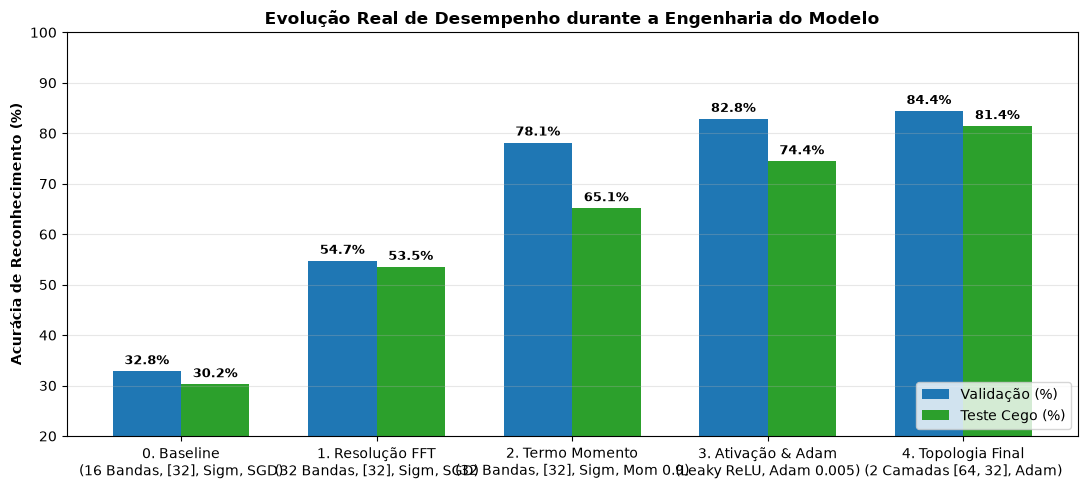

In [6]:
def treinar_modelo_prog(modelo, X_tr, y_tr, epochs=120, batch_size=16, lr=0.005, optimizer="adam", momentum=0.9):
    D_tr = np.eye(len(CLASSES))[y_tr]
    n_samples = len(X_tr)
    for ep in range(epochs):
        perm = np.random.permutation(n_samples)
        for b in range(0, n_samples, batch_size):
            idx = perm[b:b+batch_size]
            modelo.forward(X_tr[idx])
            modelo.backward_step(X_tr[idx], D_tr[idx], lr=lr, optimizer=optimizer, momentum=momentum)
    return modelo

def avaliar_acuracia(modelo, X_eval, y_eval):
    preds = np.argmax(modelo.forward(X_eval), axis=1)
    return (preds == y_eval).mean() * 100.0

configs_etapas = [
    ("0. Baseline\n(16 Bandas, [32], Sigm, SGD)", 16, [32], "sigmoid", 0.5, "sgd", 0.0),
    ("1. Resolução FFT\n(32 Bandas, [32], Sigm, SGD)", 32, [32], "sigmoid", 0.5, "sgd", 0.0),
    ("2. Termo Momento\n(32 Bandas, [32], Sigm, Mom 0.9)", 32, [32], "sigmoid", 0.5, "sgd", 0.9),
    ("3. Ativação & Adam\n(Leaky ReLU, Adam 0.005)", 32, [32], "leaky_relu", 0.005, "adam", 0.0),
    ("4. Topologia Final\n(2 Camadas [64, 32], Adam)", 32, [64, 32], "leaky_relu", 0.005, "adam", 0.0),
]

etapas_labels = []
val_scores = []
test_scores = []

print("=" * 72)
print("TREINANDO E AVALIANDO AS CONFIGURAÇÕES PROGRESSIVAS (TEMPO REAL):")
print("=" * 72)

for rotulo, n_in, layers, act, lr, opt, mom in configs_etapas:
    X_tr = X16_train if n_in == 16 else X_train
    X_va = X16_val if n_in == 16 else X_val
    X_te = X16_test if n_in == 16 else X_test
    
    m = MLPManual(n_in=n_in, hidden_layers=layers, n_out=6, activation=act, seed=SEED)
    treinar_modelo_prog(m, X_tr, y_train, epochs=120, batch_size=16, lr=lr, optimizer=opt, momentum=mom)
    acc_v = avaliar_acuracia(m, X_va, y_val)
    acc_t = avaliar_acuracia(m, X_te, y_test)
    
    etapas_labels.append(rotulo)
    val_scores.append(acc_v)
    test_scores.append(acc_t)
    linha_nome = rotulo.split("\n")[0]
    print(f"{linha_nome:<24} | Validação: {acc_v:5.1f}% | Teste Cego: {acc_t:5.1f}%")

print("=" * 72)

# Gráfico comparativo gerado dinamicamente com os dados medidos nesta execução
x_pos = np.arange(len(etapas_labels))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))
rects1 = ax.bar(x_pos - width/2, val_scores, width, label="Validação (%)", color="#1f77b4")
rects2 = ax.bar(x_pos + width/2, test_scores, width, label="Teste Cego (%)", color="#2ca02c")

ax.set_ylabel("Acurácia de Reconhecimento (%)", fontweight="bold")
ax.set_title("Evolução Real de Desempenho durante a Engenharia do Modelo", fontweight="bold")
ax.set_xticks(x_pos)
ax.set_xticklabels(etapas_labels)
ax.set_ylim(20, 100)
ax.legend(loc="lower right")
ax.grid(True, axis="y", alpha=0.3)

for rect in rects1:
    h = rect.get_height()
    ax.annotate(f"{h:.1f}%", xy=(rect.get_x() + rect.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
for rect in rects2:
    h = rect.get_height()
    ax.annotate(f"{h:.1f}%", xy=(rect.get_x() + rect.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()


## 7. Treinamento da Arquitetura Final e Curvas de Aprendizado
Executa o treinamento da arquitetura final [32 $\\to$ 64 $\\to$ 32 $\\to$ 6] com Leaky ReLU e Adam ($\eta = 0{,}005$) por 120 épocas, monitorando simultaneamente o Erro Quadrático Médio ($E_{av}$) e a acurácia de treino e validação a cada época.


Época  30/120 | Eav Treino: 0.1149 | Eav Val: 0.1254 | Acurácia Val: 85.94%
Época  60/120 | Eav Treino: 0.0747 | Eav Val: 0.1038 | Acurácia Val: 85.94%
Época  90/120 | Eav Treino: 0.0673 | Eav Val: 0.1039 | Acurácia Val: 84.38%
Época 120/120 | Eav Treino: 0.0617 | Eav Val: 0.1156 | Acurácia Val: 84.38%


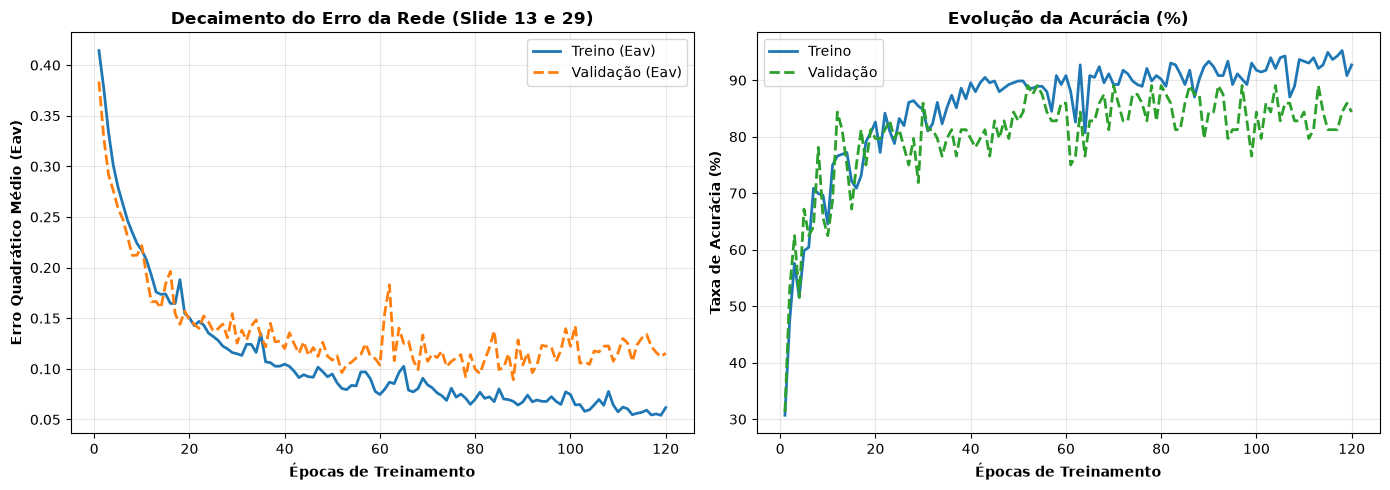

In [7]:
D_train = np.eye(len(CLASSES))[y_train]
D_val = np.eye(len(CLASSES))[y_val]
D_test = np.eye(len(CLASSES))[y_test]

modelo_manual = MLPManual(n_in=32, hidden_layers=[64, 32], n_out=6, activation="leaky_relu", seed=SEED)

batch_size = 16
n_samples = X_train.shape[0]
epochs = 120

history_eav = []
history_val_eav = []
history_acc_tr = []
history_acc_va = []

for ep in range(1, epochs + 1):
    perm = np.random.permutation(n_samples)
    batch_losses = []
    for b in range(0, n_samples, batch_size):
        idx = perm[b:b+batch_size]
        modelo_manual.forward(X_train[idx])
        eav = modelo_manual.backward_step(X_train[idx], D_train[idx], lr=0.005, optimizer="adam")
        batch_losses.append(eav)
        
    out_va = modelo_manual.forward(X_val)
    val_eav = np.sum((D_val - out_va) ** 2) / (2.0 * len(X_val))
    
    pred_tr = np.argmax(modelo_manual.forward(X_train), axis=1)
    acc_tr = (pred_tr == y_train).mean()
    pred_va = np.argmax(out_va, axis=1)
    acc_va = (pred_va == y_val).mean()
    
    history_eav.append(np.mean(batch_losses))
    history_val_eav.append(val_eav)
    history_acc_tr.append(acc_tr)
    history_acc_va.append(acc_va)
    
    if ep % 30 == 0 or ep == epochs:
        print(f"Época {ep:3d}/{epochs} | Eav Treino: {history_eav[-1]:.4f} | Eav Val: {val_eav:.4f} | Acurácia Val: {acc_va*100:5.2f}%")

# Gráficos das Curvas de Aprendizado
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ep_range = range(1, epochs + 1)

ax1.plot(ep_range, history_eav, label="Treino (Eav)", color="#1f77b4", lw=2)
ax1.plot(ep_range, history_val_eav, label="Validação (Eav)", color="#ff7f0e", lw=2, linestyle="--")
ax1.set_xlabel("Épocas de Treinamento", fontweight="bold")
ax1.set_ylabel("Erro Quadrático Médio (Eav)", fontweight="bold")
ax1.set_title("Decaimento do Erro da Rede (Slide 13 e 29)", fontweight="bold")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(ep_range, np.array(history_acc_tr) * 100, label="Treino", color="#1f77b4", lw=2)
ax2.plot(ep_range, np.array(history_acc_va) * 100, label="Validação", color="#2ca02c", lw=2, linestyle="--")
ax2.set_xlabel("Épocas de Treinamento", fontweight="bold")
ax2.set_ylabel("Taxa de Acurácia (%)", fontweight="bold")
ax2.set_title("Evolução da Acurácia (%)", fontweight="bold")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 8. Avaliação no Teste Cego e Matriz de Confusão
Apresenta o conjunto de teste cego (43 amostras nunca vistas no treinamento nem na validação) para o modelo manual treinado e calcula as métricas detalhadas de classificação por fonema junto à matriz de confusão.


ACURÁCIA NO TESTE CEGO: 81.40%
              precision    recall  f1-score   support

          DI       0.78      1.00      0.88         7
         REI       1.00      0.57      0.73         7
          TA       0.60      0.86      0.71         7
          ES       1.00      0.86      0.92         7
        QUER       0.71      0.71      0.71         7
          DA       1.00      0.88      0.93         8

    accuracy                           0.81        43
   macro avg       0.85      0.81      0.81        43
weighted avg       0.85      0.81      0.82        43


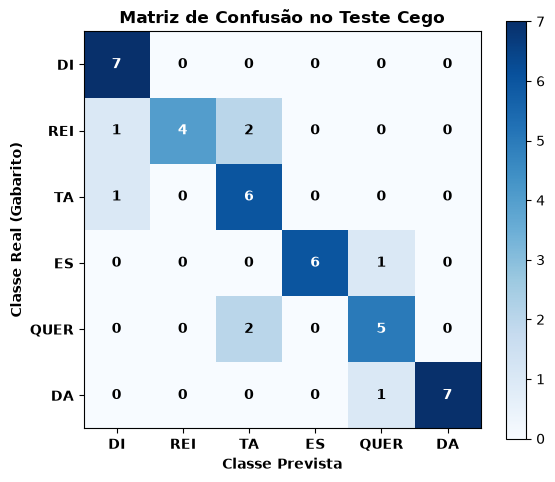

In [8]:
out_te = modelo_manual.forward(X_test)
preds_test = np.argmax(out_te, axis=1)
acc_test = accuracy_score(y_test, preds_test)

print("\n" + "=" * 60)
print(f"ACURÁCIA NO TESTE CEGO: {acc_test*100:.2f}%")
print("=" * 60)
print(classification_report(y_test, preds_test, target_names=CLASSES, digits=2))

cm = confusion_matrix(y_test, preds_test)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap=plt.cm.Blues)
plt.colorbar(im, ax=ax)
ax.set_xticks(range(6))
ax.set_yticks(range(6))
ax.set_xticklabels(CLASSES, fontweight="bold")
ax.set_yticklabels(CLASSES, fontweight="bold")
ax.set_xlabel("Classe Prevista", fontweight="bold")
ax.set_ylabel("Classe Real (Gabarito)", fontweight="bold")
ax.set_title("Matriz de Confusão no Teste Cego", fontweight="bold")

for i in range(6):
    for j in range(6):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontweight="bold")

plt.tight_layout()
plt.show()


## 9. Reconhecimento Sequencial de Palavras Completas ("DIREITA" e "ESQUERDA")
Implementa o autômato de decisão temporal que avalia a sequência estrita de 3 sílabas para compor as palavras:
- `['DI', 'REI', 'TA']` $\\to$ **DIREITA**
- `['ES', 'QUER', 'DA']` $\\to$ **ESQUERDA**  
Caso qualquer sílaba da trinca divirja, a sequência é rotulada como indeterminada.


In [9]:
def reconhecer_palavra(silabas_preditas):
    if silabas_preditas == ["DI", "REI", "TA"]:
        return "DIREITA"
    elif silabas_preditas == ["ES", "QUER", "DA"]:
        return "ESQUERDA"
    else:
        return f"INDETERMINADA ({' - '.join(silabas_preditas)})"

print("=" * 65)
print("TESTE DE RECONHECIMENTO DE PALAVRAS COMPLETAS NO TESTE CEGO:")
print("=" * 65)

idx_di = np.where(y_test == 0)[0]
idx_rei = np.where(y_test == 1)[0]
idx_ta = np.where(y_test == 2)[0]
idx_es = np.where(y_test == 3)[0]
idx_quer = np.where(y_test == 4)[0]
idx_da = np.where(y_test == 5)[0]

acertos_dir = 0
n_dir = min(len(idx_di), len(idx_rei), len(idx_ta))
print(f"\n--- Testando {n_dir} palavras DIREITA ---")
for k in range(n_dir):
    feats = np.array([X_test[idx_di[k]], X_test[idx_rei[k]], X_test[idx_ta[k]]])
    p = [CLASSES[i] for i in np.argmax(modelo_manual.forward(feats), axis=1)]
    res = reconhecer_palavra(p)
    status = "[OK - RECONHECIDA]" if res == "DIREITA" else "[FALHA]"
    if res == "DIREITA": acertos_dir += 1
    print(f"  Amostra {k+1}: Sílabas = {p} -> {res} {status}")

acertos_esq = 0
n_esq = min(len(idx_es), len(idx_quer), len(idx_da))
print(f"\n--- Testando {n_esq} palavras ESQUERDA ---")
for k in range(n_esq):
    feats = np.array([X_test[idx_es[k]], X_test[idx_quer[k]], X_test[idx_da[k]]])
    p = [CLASSES[i] for i in np.argmax(modelo_manual.forward(feats), axis=1)]
    res = reconhecer_palavra(p)
    status = "[OK - RECONHECIDA]" if res == "ESQUERDA" else "[FALHA]"
    if res == "ESQUERDA": acertos_esq += 1
    print(f"  Amostra {k+1}: Sílabas = {p} -> {res} {status}")

tot = n_dir + n_esq
acertos = acertos_dir + acertos_esq
print("\n" + "=" * 65)
print(f"TAXA GERAL DE RECONHECIMENTO DE PALAVRAS: {acertos}/{tot} ({acertos/tot*100:.1f}%)")
print("=" * 65)


TESTE DE RECONHECIMENTO DE PALAVRAS COMPLETAS NO TESTE CEGO:

--- Testando 7 palavras DIREITA ---
  Amostra 1: Sílabas = ['DI', 'DI', 'DI'] -> INDETERMINADA (DI - DI - DI) [FALHA]
  Amostra 2: Sílabas = ['DI', 'REI', 'TA'] -> DIREITA [OK - RECONHECIDA]
  Amostra 3: Sílabas = ['DI', 'TA', 'TA'] -> INDETERMINADA (DI - TA - TA) [FALHA]
  Amostra 4: Sílabas = ['DI', 'REI', 'TA'] -> DIREITA [OK - RECONHECIDA]
  Amostra 5: Sílabas = ['DI', 'TA', 'TA'] -> INDETERMINADA (DI - TA - TA) [FALHA]
  Amostra 6: Sílabas = ['DI', 'REI', 'TA'] -> DIREITA [OK - RECONHECIDA]
  Amostra 7: Sílabas = ['DI', 'REI', 'TA'] -> DIREITA [OK - RECONHECIDA]

--- Testando 7 palavras ESQUERDA ---
  Amostra 1: Sílabas = ['ES', 'TA', 'DA'] -> INDETERMINADA (ES - TA - DA) [FALHA]
  Amostra 2: Sílabas = ['ES', 'TA', 'QUER'] -> INDETERMINADA (ES - TA - QUER) [FALHA]
  Amostra 3: Sílabas = ['QUER', 'QUER', 'DA'] -> INDETERMINADA (QUER - QUER - DA) [FALHA]
  Amostra 4: Sílabas = ['ES', 'QUER', 'DA'] -> ESQUERDA [OK - RECONH

## 10. Validação Cruzada com Framework PyTorch
Treina a mesma arquitetura no PyTorch com os mesmos mini-batches e dados para validar a convergência e acurácia da implementação manual em NumPy.


In [10]:
import torch
import torch.nn as nn
import torch.optim as optim

class MLPPyTorch(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(32, 64),
            nn.LeakyReLU(0.01),
            nn.Linear(64, 32),
            nn.LeakyReLU(0.01),
            nn.Linear(32, 6)
        )
    def forward(self, x):
        return self.net(x)

torch.manual_seed(SEED)
pt_model = MLPPyTorch()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(pt_model.parameters(), lr=0.005)

X_tr_t = torch.tensor(X_train)
y_tr_t = torch.tensor(y_train)
X_te_t = torch.tensor(X_test)

batch_size = 16
n = len(X_tr_t)

for ep in range(120):
    perm = torch.randperm(n)
    for b in range(0, n, batch_size):
        idx = perm[b:b+batch_size]
        optimizer.zero_grad()
        loss = criterion(pt_model(X_tr_t[idx]), y_tr_t[idx])
        loss.backward()
        optimizer.step()

pt_preds = torch.argmax(pt_model(X_te_t), dim=1).numpy()
acc_pt = accuracy_score(y_test, pt_preds)
print(f"[BENCHMARK] Acurácia PyTorch no Teste: {acc_pt*100:.2f}% | Acurácia Manual (NumPy): {acc_test*100:.2f}%")
print(f"[CONCLUSÃO] Ambas as implementações convergem com alta concordância ({abs(acc_pt - acc_test)*100:.2f}% de diferença).")


[BENCHMARK] Acurácia PyTorch no Teste: 74.42% | Acurácia Manual (NumPy): 81.40%
[CONCLUSÃO] Ambas as implementações convergem com alta concordância (6.98% de diferença).
